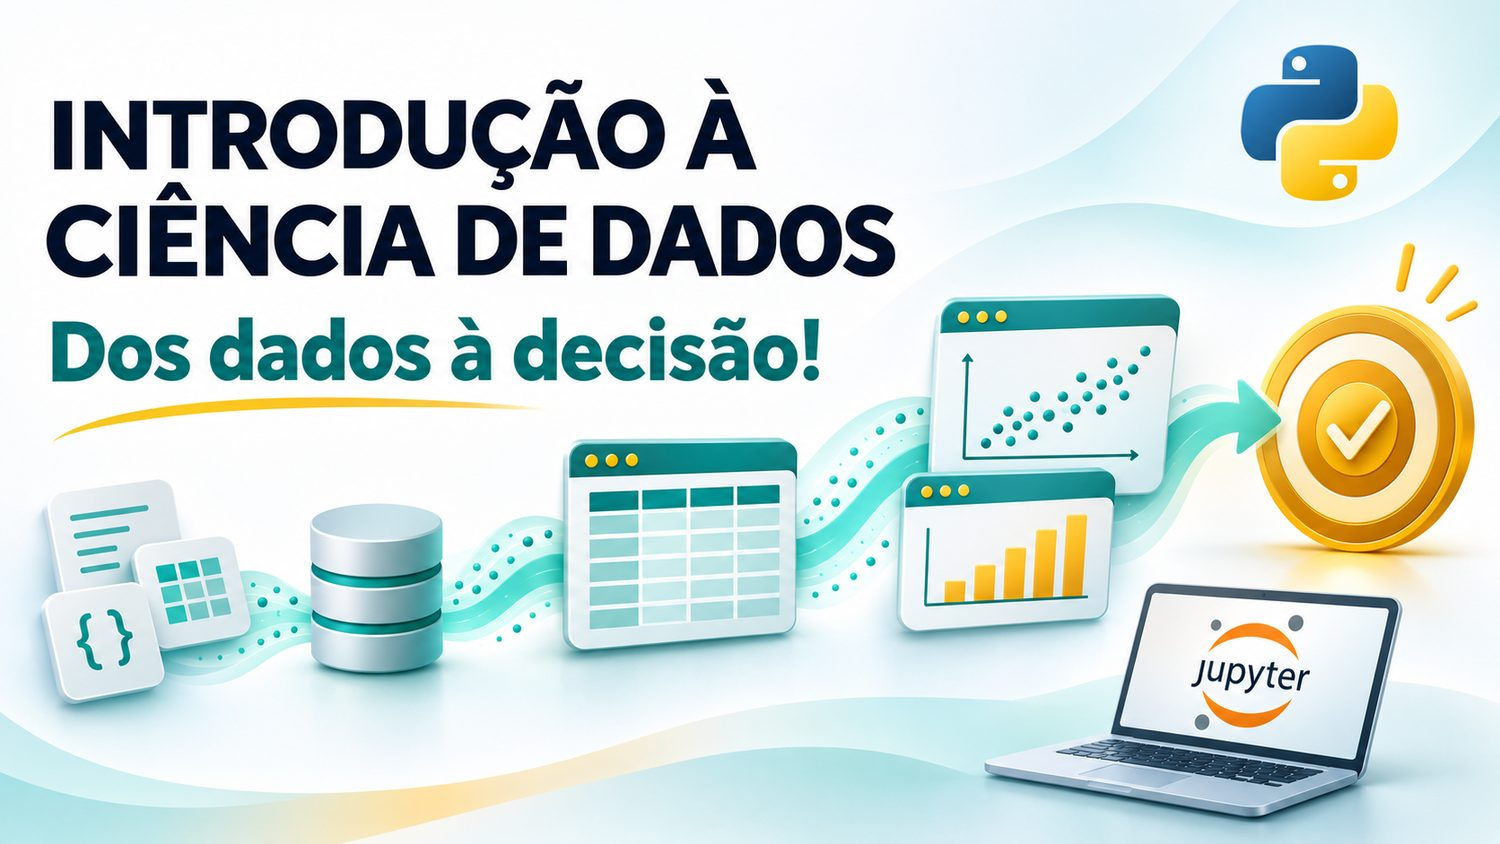

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_6_aprendizagem_nao_supervisionada/02_Avaliar_sem_Rotulos.ipynb)

# Capítulo 2 – Quantos grupos? Avaliar sem rótulos

O K-Means devolve sempre os k grupos que lhe pedimos. Ficam duas perguntas por responder: **que valor de k escolher**, e **se os grupos encontrados são reais** ou apenas fatias de uma nuvem contínua. Sem alvo, não há matriz de confusão nem erro médio. Este capítulo apresenta as ferramentas que existem e, sobretudo, o que cada uma consegue e não consegue dizer.

> **Objetivos:** usar a curva da inércia (o «cotovelo») e conhecer os seus limites; calcular o coeficiente de silhueta de raiz e interpretá-lo; ler um gráfico de silhuetas; testar a estabilidade de um agrupamento; comparar com dados sem estrutura; distinguir validação interna, externa e por utilidade.

**Pré-requisitos:** capítulo 1.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_utilizadores(n=3000, semente=53, com_perfil=False):
    """Gera utilizadores de uma aplicação fictícia de aprendizagem de línguas (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    perfil = rng.choice(4, n, p=[0.34, 0.22, 0.30, 0.14])
    # por perfil: sessões por semana, minutos por sessão, dias seguidos, % à noite, exercícios de fala, % de erros
    centros = np.array([[9.5, 6.0, 38, 30, 2.0, 22],
                        [2.2, 34.0, 3, 55, 6.0, 17],
                        [1.3, 7.0, 1, 45, 0.6, 31],
                        [7.5, 27.0, 55, 40, 14.0, 12]])
    desvios = np.array([[2.2, 1.8, 22, 16, 1.6, 6], [0.8, 8.0, 2.5, 18, 3.0, 5], [0.7, 3.0, 1.2, 20, 0.7, 8], [2.0, 7.0, 30, 17, 5.0, 4]])
    v = rng.normal(centros[perfil], desvios[perfil])
    sessoes = v[:, 0].clip(0.2, 21).round(1)
    minutos = v[:, 1].clip(2, 70).round(1)
    licoes = (sessoes * minutos / 5.5 * rng.normal(1, 0.12, n)).clip(0.2).round(1)
    tabela = pd.DataFrame({"sessoes_semana": sessoes, "minutos_sessao": minutos, "licoes_semana": licoes,
                           "dias_seguidos": v[:, 2].clip(0, 200).round(), "pct_noite": v[:, 3].clip(0, 100).round(),
                           "exercicios_fala": v[:, 4].clip(0, 40).round(1), "pct_erros": v[:, 5].clip(2, 60).round(1),
                           "meses_na_app": rng.gamma(1.8, 5, n).clip(0.5, 48).round(1)})
    tabela["premium"] = rng.random(n) < np.array([0.12, 0.25, 0.03, 0.55])[perfil]
    if com_perfil:                                   # só para verificação: num caso real esta coluna não existe
        tabela["perfil_verdadeiro"] = perfil
    return tabela


utilizadores = gerar_utilizadores()
utilizadores.head()

,sessoes_semana,minutos_sessao,licoes_semana,dias_seguidos,pct_noite,exercicios_fala,pct_erros,meses_na_app,premium
0,10.3,9.2,11.2,25.0,49.0,0.9,15.8,17.9,False
1,1.4,7.0,1.7,0.0,62.0,0.0,32.3,3.2,False
2,9.5,5.1,8.7,52.0,58.0,3.7,28.6,22.9,False
3,2.7,25.2,13.0,29.0,52.0,13.3,13.1,8.4,False
4,11.7,8.2,15.5,39.0,14.0,0.0,21.7,16.4,False


In [3]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

CORES = [AZUL, LARANJA, VERDE, VIOLETA, AVISO, MAU, CINZA, TINTA]
numericas = [c for c in utilizadores.columns if c != "premium"]
Z = StandardScaler().fit_transform(utilizadores[numericas])
modelos = {k: KMeans(k, n_init=10, random_state=0).fit(Z) for k in range(1, 11)}

## Porque não basta a inércia

A inércia mede quão compactos são os grupos, e é o que o K-Means minimiza. Parece a métrica natural para escolher k. Mas tem um defeito: **desce sempre** quando k aumenta. Com um grupo por utilizador, a inércia é zero.

É o mesmo problema do erro de treino no módulo 5: melhora sempre com a complexidade e por isso não serve, sozinho, para escolher.

### O método do cotovelo

O que se pode usar é a **forma** da curva. Enquanto um grupo novo separa utilizadores realmente diferentes, a inércia cai muito. Quando os grupos novos apenas partem grupos existentes, a queda é pequena. Procura-se o ponto em que a curva dobra: o «cotovelo».

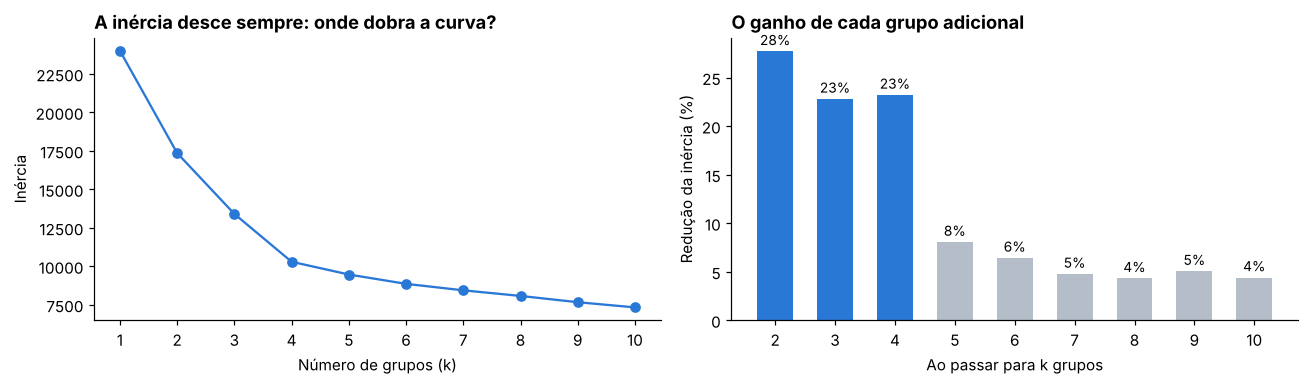

In [4]:
inercias = pd.Series({k: m.inertia_ for k, m in modelos.items()})
ganho = (-inercias.diff() / inercias.shift() * 100).dropna()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))
ax1.plot(inercias.index, inercias, "o-", color=AZUL)
ax1.set_xticks(inercias.index)
ax1.set_xlabel("Número de grupos (k)")
ax1.set_ylabel("Inércia")
ax1.set_title("A inércia desce sempre: onde dobra a curva?")
barras = ax2.bar(ganho.index, ganho, color=[AZUL if k <= 4 else CINZA for k in ganho.index], width=0.6)
ax2.bar_label(barras, fmt="%.0f%%", padding=2, fontsize=9)
ax2.set_xticks(ganho.index)
ax2.set_xlabel("Ao passar para k grupos")
ax2.set_ylabel("Redução da inércia (%)")
ax2.set_title("O ganho de cada grupo adicional")
plt.tight_layout()
plt.show()

O segundo, o terceiro e o quarto grupos reduzem a inércia em mais de 20% cada. A partir do quinto, os ganhos ficam abaixo de 10% e vão diminuindo devagar. O cotovelo está em **k = 4**.

O método é simples e tem limites:

- o cotovelo é muitas vezes **pouco nítido**, e duas pessoas leem-no em sítios diferentes;
- mesmo em dados **sem grupos nenhuns** a curva desce e pode parecer ter um cotovelo;
- só olha para a compactação, e não para a **separação** entre grupos.

## O coeficiente de silhueta

A silhueta olha para as duas coisas. Para cada utilizador, compara:

- **a**: a distância média aos outros membros do **seu** grupo (quer-se pequena);
- **b**: a distância média aos membros do grupo **vizinho mais próximo** (quer-se grande).

> **silhueta = (b − a) ÷ máximo(a, b)**

| Valor | Significado |
| --- | --- |
| Perto de **+1** | Muito mais perto do seu grupo do que do vizinho: bem colocado |
| Perto de **0** | Na fronteira entre dois grupos |
| **Negativo** | Mais perto do grupo vizinho do que do seu: provavelmente mal colocado |

### Calcular de raiz

In [5]:
def silhueta_de_um(i, Z, grupos):
    """Coeficiente de silhueta do ponto i."""
    distancias = np.sqrt(((Z - Z[i]) ** 2).sum(axis=1))
    meu = grupos == grupos[i]
    a = distancias[meu].sum() / (meu.sum() - 1)                        # média aos outros do meu grupo (sem contar comigo)
    b = min(distancias[grupos == g].mean() for g in np.unique(grupos) if g != grupos[i])
    return (b - a) / max(a, b)


grupos4 = modelos[4].labels_
for i in [0, 1, 2]:
    print(f"Utilizador {i}: grupo {grupos4[i]}, silhueta {silhueta_de_um(i, Z, grupos4):+.3f}")

Utilizador 0: grupo 0, silhueta +0.311
Utilizador 1: grupo 3, silhueta +0.447
Utilizador 2: grupo 0, silhueta +0.203


In [6]:
from sklearn.metrics import silhouette_samples, silhouette_score

amostra = np.random.default_rng(0).choice(len(Z), 300, replace=False)
nossas = np.array([silhueta_de_um(i, Z, grupos4) for i in amostra])
oficiais = silhouette_samples(Z, grupos4)
print(f"Maior diferença para o scikit-learn, em 300 utilizadores: {np.abs(nossas - oficiais[amostra]).max():.2e}")
print(f"Silhueta média de todos os utilizadores (k = 4): {silhouette_score(Z, grupos4):.3f}")

Maior diferença para o scikit-learn, em 300 utilizadores: 2.60e-15
Silhueta média de todos os utilizadores (k = 4): 0.343


A **silhueta média** de todos os pontos resume o agrupamento num número. Ao contrário da inércia, **não melhora automaticamente** com k: partir um grupo natural em dois aproxima os grupos vizinhos e baixa o valor de b.

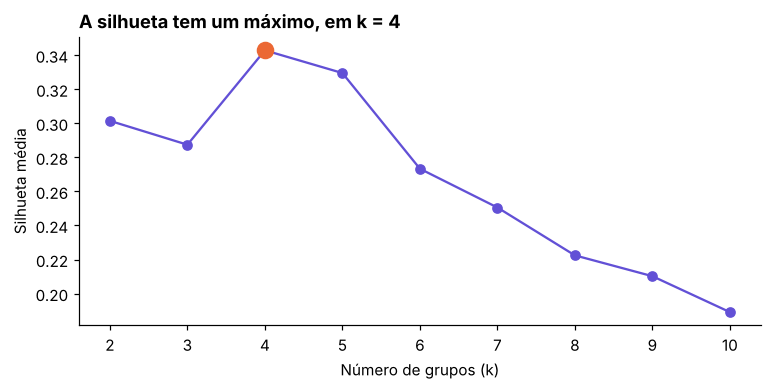

In [7]:
silhuetas = pd.Series({k: silhouette_score(Z, modelos[k].labels_) for k in range(2, 11)})
melhor_k = int(silhuetas.idxmax())

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(silhuetas.index, silhuetas, "o-", color=VIOLETA)
ax.scatter([melhor_k], [silhuetas.max()], s=110, color=LARANJA, zorder=3)
ax.set_xticks(silhuetas.index)
ax.set_xlabel("Número de grupos (k)")
ax.set_ylabel("Silhueta média")
ax.set_title(f"A silhueta tem um máximo, em k = {melhor_k}")
plt.show()

A silhueta confirma o cotovelo: o máximo está em k = 4.

O valor em si merece atenção. Como referência habitual: acima de 0,5 os grupos estão bem separados; entre 0,25 e 0,5 há estrutura, com sobreposição; abaixo de 0,25 a estrutura é fraca. O nosso valor está na zona intermédia: **há grupos, e não estão isolados uns dos outros**. Faz sentido: entre «hábito diário» e «intensivo» há utilizadores a meio caminho.

### O gráfico de silhuetas

A média esconde a distribuição (módulo 3, capítulo 3). O gráfico de silhuetas mostra o valor de **cada** utilizador, grupo a grupo.

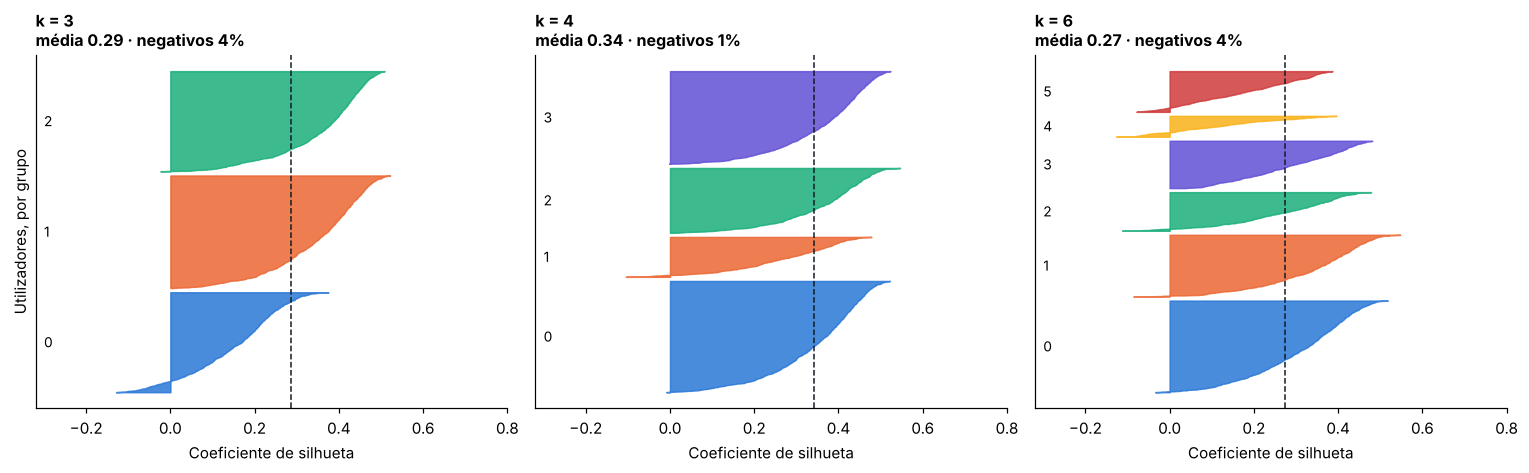

In [8]:
def grafico_de_silhuetas(ax, Z, grupos, titulo):
    valores = silhouette_samples(Z, grupos)
    base = 0
    for g in np.unique(grupos):
        v = np.sort(valores[grupos == g])
        ax.fill_betweenx(np.arange(base, base + len(v)), 0, v, color=CORES[g], alpha=0.85)
        ax.text(-0.3, base + len(v) / 2, f"{g}", va="center", fontsize=9)
        base += len(v) + 40
    ax.axvline(valores.mean(), color=TINTA, ls="--", lw=1)
    ax.set_xlim(-0.32, 0.8)
    ax.set_yticks([])
    ax.set_xlabel("Coeficiente de silhueta")
    ax.set_title(f"{titulo}\nmédia {valores.mean():.2f} · negativos {np.mean(valores < 0):.0%}", fontsize=10.5)


fig, eixos = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, k in zip(eixos, [3, 4, 6]):
    grafico_de_silhuetas(ax, Z, modelos[k].labels_, f"k = {k}")
eixos[0].set_ylabel("Utilizadores, por grupo")
plt.tight_layout()
plt.show()

Cada «faca» é um grupo: a altura é o número de utilizadores, a largura é a silhueta de cada um, do menor para o maior. A linha tracejada é a média.

Num bom agrupamento, **todas as facas passam a linha média** e há poucos valores negativos.

- Com **k = 3**, um dos grupos mal chega à média e tem uma cauda de valores negativos: junta utilizadores de dois perfis.
- Com **k = 4**, as quatro facas têm forma parecida.
- Com **k = 6**, aparecem grupos finos, que mal chegam à média, e mais valores negativos: grupos naturais foram partidos.

## Os grupos são estáveis?

Um agrupamento real deve resistir a pequenas mudanças nos dados. Se tirarmos uma amostra diferente de utilizadores e os grupos mudarem por completo, eram um acaso.

Para comparar dois agrupamentos usa-se o **índice de Rand ajustado** (ARI). Olha para todos os pares de utilizadores e conta em quantos os dois agrupamentos concordam (juntos em ambos, ou separados em ambos), descontando a concordância que haveria por acaso. Vale 1 para agrupamentos iguais e cerca de 0 para agrupamentos sem relação. Não depende dos números dados aos grupos.

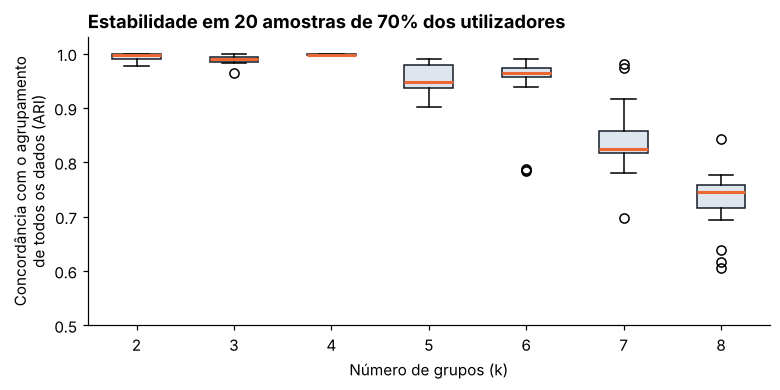

In [9]:
from sklearn.metrics import adjusted_rand_score


def estabilidade(Z, k, repeticoes=20, fracao=0.7, semente=0):
    """Agrupa várias amostras e mede a concordância com o agrupamento de todos os dados."""
    rng = np.random.default_rng(semente)
    referencia = KMeans(k, n_init=10, random_state=0).fit(Z)
    valores = []
    for r in range(repeticoes):
        amostra = rng.choice(len(Z), int(fracao * len(Z)), replace=False)
        parcial = KMeans(k, n_init=10, random_state=r).fit(Z[amostra])
        valores.append(adjusted_rand_score(referencia.labels_, parcial.predict(Z)))     # comparados em todos os utilizadores
    return np.array(valores)


estavel = {k: estabilidade(Z, k) for k in range(2, 9)}
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.boxplot(list(estavel.values()), tick_labels=list(estavel), widths=0.5, patch_artist=True,
           boxprops={"facecolor": "#dfe5ec", "edgecolor": TINTA}, medianprops={"color": LARANJA, "linewidth": 2})
ax.set_xlabel("Número de grupos (k)")
ax.set_ylabel("Concordância com o agrupamento\nde todos os dados (ARI)")
ax.set_ylim(0.5, 1.03)
ax.set_title("Estabilidade em 20 amostras de 70% dos utilizadores")
plt.show()

Com k = 4, as 20 amostras dão praticamente o mesmo agrupamento. Com valores maiores de k, os resultados dispersam: os grupos adicionais são traçados em sítios diferentes conforme a amostra, sinal de que não correspondem a nada de fixo nos dados.

Um agrupamento pode ser estável sem ser útil (com k = 2 também o é). A estabilidade é uma condição necessária, e não suficiente.

## Comparar com dados sem estrutura

O capítulo 1 mostrou que o K-Means encontra «grupos» em pontos ao acaso. Uma forma de saber se os nossos são melhores do que isso é criar uma **versão dos dados sem grupos** e comparar.

Baralhamos cada coluna de forma independente. Cada coluna mantém exatamente a sua distribuição, mas desaparecem as relações entre colunas, que são o que cria os grupos. É a mesma ideia de baralhar o alvo no módulo 5.

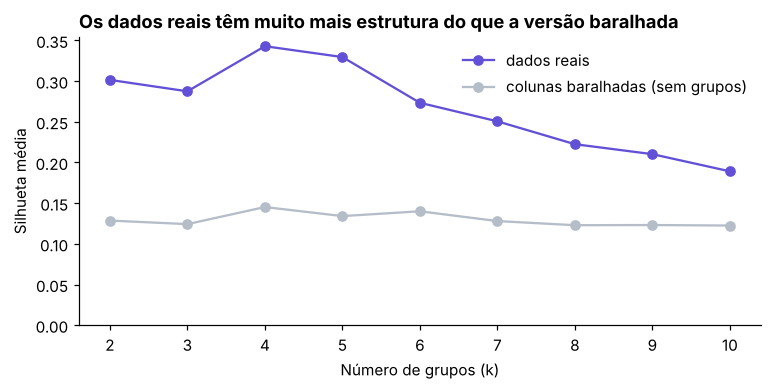

In [10]:
rng = np.random.default_rng(0)
Z_baralhado = np.column_stack([rng.permutation(Z[:, j]) for j in range(Z.shape[1])])
silhuetas_baralhado = pd.Series({k: silhouette_score(Z_baralhado, KMeans(k, n_init=5, random_state=0).fit_predict(Z_baralhado)) for k in range(2, 11)})

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(silhuetas.index, silhuetas, "o-", color=VIOLETA, label="dados reais")
ax.plot(silhuetas_baralhado.index, silhuetas_baralhado, "o-", color=CINZA, label="colunas baralhadas (sem grupos)")
ax.set_xticks(silhuetas.index)
ax.set_xlabel("Número de grupos (k)")
ax.set_ylabel("Silhueta média")
ax.set_ylim(0, None)
ax.set_title("Os dados reais têm muito mais estrutura do que a versão baralhada")
ax.legend(frameon=False)
plt.show()

A linha cinzenta é o que o K-Means consegue quando **não há nada para encontrar**: uma silhueta baixa e quase igual para todos os valores de k. A dos dados reais fica bem acima e tem um pico em k = 4. A diferença entre as duas é a evidência de que os grupos existem.

Sem esta comparação, um valor de silhueta isolado é difícil de julgar.

## Três formas de validar

| Validação | Pergunta | Ferramentas | Limite |
| --- | --- | --- | --- |
| **Interna** | Os grupos são compactos e separados? | Inércia, silhueta | Mede a geometria, e não o significado |
| **Por estabilidade** | Os grupos repetem-se com outros dados? | Amostras repetidas, ARI | Um agrupamento inútil pode ser estável |
| **Externa** | Os grupos coincidem com algo que se sabe? | Colunas que ficaram de fora, rótulos de referência | Raramente há rótulos; se houvesse, usava-se um modelo supervisionado |
| **Por utilidade** | Os grupos servem para decidir? | Perfis com nome, decisões diferentes por grupo, uma experiência | Exige conhecimento do problema |

As duas primeiras fazem-se sempre. A última é a que decide. Um agrupamento com silhueta modesta que permite à equipa comunicar de forma diferente com cada grupo vale mais do que um agrupamento geometricamente perfeito que ninguém sabe usar.

### Um luxo dos dados sintéticos

Como gerámos os dados, sabemos de que perfil saiu cada utilizador. Num caso real esta coluna **não existe**; usamo-la aqui só para confirmar se as ferramentas apontaram na direção certa.

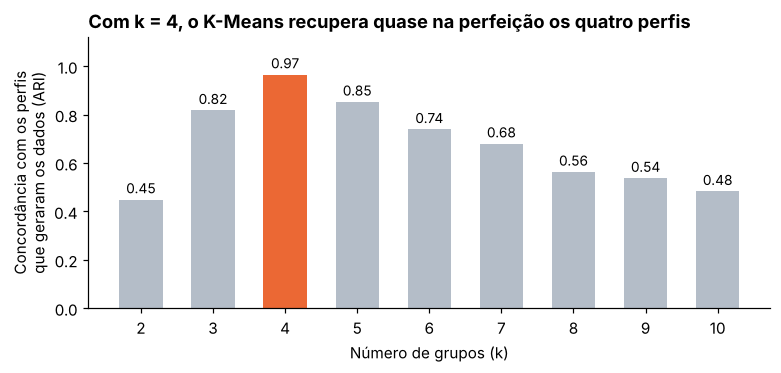

grupo encontrado      0    1    2    3
perfil verdadeiro                     
0                  1073    0    0   14
1                     1    0  611    2
2                     0    0    3  885
3                     7  388   16    0


In [11]:
verdade = gerar_utilizadores(com_perfil=True)["perfil_verdadeiro"]
ari = pd.Series({k: adjusted_rand_score(verdade, modelos[k].labels_) for k in range(2, 11)})

fig, ax = plt.subplots(figsize=(8, 3.2))
barras = ax.bar(ari.index, ari, color=[LARANJA if k == 4 else CINZA for k in ari.index], width=0.6)
ax.bar_label(barras, fmt="%.2f", padding=2, fontsize=9)
ax.set_xticks(ari.index)
ax.set_ylim(0, 1.12)
ax.set_xlabel("Número de grupos (k)")
ax.set_ylabel("Concordância com os perfis\nque geraram os dados (ARI)")
ax.set_title("Com k = 4, o K-Means recupera quase na perfeição os quatro perfis")
plt.show()

print(pd.crosstab(verdade, modelos[4].labels_, rownames=["perfil verdadeiro"], colnames=["grupo encontrado"]))

O cotovelo, a silhueta e a estabilidade apontaram todos para k = 4, e é esse o número de perfis com que os dados foram gerados. A tabela mostra que cada perfil caiu quase inteiro num só grupo; os poucos utilizadores fora da diagonal são os que estavam na fronteira.

Nem sempre corre assim. Em dados reais, os critérios costumam discordar, e a resposta honesta a «quantos grupos há?» é muitas vezes «entre três e cinco, conforme o pormenor que for útil».

## Um roteiro para escolher k

1. **Definir as colunas e a escala** a partir da pergunta. É a decisão que mais pesa.
2. **Correr vários valores de k** e desenhar a inércia e a silhueta.
3. **Olhar para os gráficos de silhuetas** dos candidatos, e não só para a média.
4. **Testar a estabilidade** dos candidatos.
5. **Comparar com dados baralhados**, para saber se há estrutura.
6. **Descrever os grupos** de cada candidato e ficar com o agrupamento que se consegue **explicar e usar**.

## Exercícios

### `Exercício 1` – Silhueta à mão

Um ponto P pertence ao grupo A. As distâncias de P aos outros dois pontos do grupo A são 1 e 3. As distâncias aos três pontos do grupo B são 4, 6 e 8, e aos dois pontos do grupo C são 3 e 5. Calcula a, b e a silhueta de P. P está bem colocado?

<details>
<summary><b>Ver uma solução possível</b></summary>

- a = (1 + 3) ÷ 2 = **2**.
- Distância média a B = 6; a C = 4. O grupo vizinho mais próximo é C: b = **4**.
- Silhueta = (4 − 2) ÷ máximo(2, 4) = 2 ÷ 4 = **0,5**.

Está razoavelmente bem colocado: em média, está duas vezes mais perto do seu grupo do que do grupo vizinho.

</details>

### `Exercício 2` – Quem está na fronteira?

Com k = 4, encontra os utilizadores com silhueta negativa. Quantos são? Compara as médias das suas colunas com as do grupo a que foram atribuídos. Para que servem estes utilizadores à equipa da aplicação?

In [12]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
valores = silhouette_samples(Z, grupos4)
tabela = utilizadores[numericas].assign(grupo=grupos4, fronteira=valores < 0)
print("Com silhueta negativa:", int((valores < 0).sum()), f"({np.mean(valores < 0):.1%})")
print(tabela.groupby(["grupo", "fronteira"])[["sessoes_semana", "minutos_sessao", "dias_seguidos", "exercicios_fala"]].mean().round(1))
```

São uma pequena percentagem. Em cada grupo, os utilizadores da fronteira têm valores intermédios, a caminho do perfil de outro grupo. Podem ser os mais interessantes: um utilizador «de hábito diário» com valores a aproximar-se dos do grupo «a desistir» é um candidato natural a uma notificação.

</details>

### `Exercício 3` – O cotovelo em dados sem grupos

Desenha a curva da inércia (k de 1 a 10) para os dados baralhados `Z_baralhado`, ao lado da dos dados reais. Seria possível «ver» um cotovelo na curva dos dados baralhados? O que conclui sobre o método?

In [13]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
baralhado = pd.Series({k: KMeans(k, n_init=5, random_state=0).fit(Z_baralhado).inertia_ for k in range(1, 11)})
plt.plot(inercias.index, inercias, "o-", label="dados reais")
plt.plot(baralhado.index, baralhado, "o-", label="baralhados")
plt.xlabel("k"); plt.ylabel("Inércia"); plt.legend(); plt.show()
print((-baralhado.diff() / baralhado.shift() * 100).dropna().round(0).to_dict())
```

A curva dos dados baralhados também desce, de forma suave, com ganhos que vão diminuindo aos poucos. Não há uma dobra nítida, mas quem estiver à procura de um cotovelo consegue quase sempre convencer-se de que o vê. Nos dados reais a queda até k = 4 é muito mais acentuada. O método é útil **por comparação**; sozinho, convida a ver estrutura onde não há.

</details>

### `Exercício 4` – Só duas colunas

Repete a escolha de k (silhueta média, k de 2 a 8) usando apenas `sessoes_semana` e `minutos_sessao` normalizadas. A silhueta é maior ou menor do que com as oito colunas? Porquê? Isso quer dizer que o agrupamento é melhor?

In [14]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
Z2 = StandardScaler().fit_transform(utilizadores[["sessoes_semana", "minutos_sessao"]])
for k in range(2, 9):
    g = KMeans(k, n_init=10, random_state=0).fit_predict(Z2)
    print(f"k = {k}: silhueta {silhouette_score(Z2, g):.3f} | concordância com os perfis verdadeiros {adjusted_rand_score(verdade, g):.2f}")
```

A silhueta é bastante mais alta com duas colunas: com menos dimensões os pontos ficam mais concentrados e há menos ruído a afastar os membros de cada grupo. Mas uma silhueta mais alta **não significa** um agrupamento mais útil: silhuetas calculadas com colunas diferentes não são comparáveis, porque medem distâncias em espaços diferentes. A silhueta serve para comparar valores de k com as **mesmas** colunas.

</details>

## Verifica o que aprendeste

- [ ] Sei porque a inércia não serve, sozinha, para escolher k.
- [ ] Sei usar o método do cotovelo e conheço os seus limites.
- [ ] Sei calcular e interpretar o coeficiente de silhueta.
- [ ] Sei ler um gráfico de silhuetas.
- [ ] Sei testar a estabilidade de um agrupamento.
- [ ] Sei comparar com uma versão dos dados sem estrutura.
- [ ] Sei distinguir validação interna, externa e por utilidade.

## Leitura recomendada

- https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation
- https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html
- https://en.wikipedia.org/wiki/Silhouette_(clustering)
- https://en.wikipedia.org/wiki/Rand_index